Generation 1: Best = 11011, Fitness = 729
Generation 2: Best = 11011, Fitness = 729
Generation 3: Best = 11111, Fitness = 961


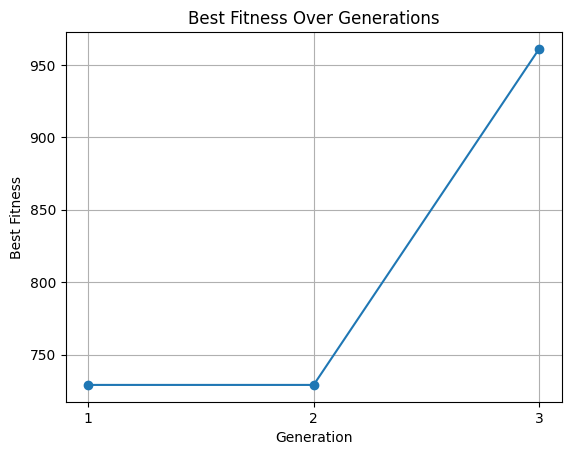

In [3]:

import random
import matplotlib.pyplot as plt

random.seed(42)

def init(n, b):
    return [''.join(random.choice('01') for _ in range(b)) for _ in range(n)]

def fit(pop):
    return [int(x, 2) ** 2 for x in pop]

def select(pop, f):
    return random.choices(pop, weights=f, k=2)

def cross(p1, p2):
    pt = random.randint(1, len(p1) - 1)
    c1 = p1[:pt] + p2[pt:]
    c2 = p2[:pt] + p1[pt:]
    return c1, c2

def mut(x, r):
    return ''.join(
        bit if random.random() > r else str(1 - int(bit))
        for bit in x
    )

def ga(n, b, r, g):
    pop = init(n, b)
    hist = []

    for i in range(g):
        f = fit(pop)
        new = []

        for _ in range(n // 2):
            p1, p2 = select(pop, f)
            c1, c2 = cross(p1, p2)
            c1 = mut(c1, r)
            c2 = mut(c2, r)
            new.extend([c1, c2])

        pop = new
        best = max(pop, key=lambda x: int(x, 2) ** 2)
        bf = int(best, 2) ** 2
        hist.append(bf)

        print(f"Generation {i + 1}: Best = {best}, Fitness = {bf}")

    plt.plot(range(1, g + 1), hist, marker='o')
    plt.title('Best Fitness Over Generations')
    plt.xlabel('Generation')
    plt.ylabel('Best Fitness')
    plt.grid(True)
    plt.xticks(range(1, g + 1))
    plt.show()

    return pop

n = 4
b = 5
r = 0.1
g = 3

final = ga(n, b, r, g)
